Name: Nadya Renata Siahaan, Alena Destria Pramesti  
NIM : 093, 254  
Class : 2025INT  
Exercise 6 Pemteks — Text Similarity

**Task:** Try applying the **text similarity** on the text you have **feature engineering from the previous exercise** and analyze the given results.

Pada tugas ini, text similarity diterapkan pada **hasil feature engineering Exercise 5** (teks dari website `http://home.wezm.net`, satu kalimat = satu dokumen). Metode yang dipakai mengikuti materi dosen:

1. **Cosine Similarity** pada Bag of Words, TF-IDF, dan One Hot (binary)
2. **Jaccard Similarity** pada One Hot (binary)
3. **Cosine Similarity** pada vektor dokumen **Word2Vec** dan **FastText** (perluasan dari materi, karena fitur ini juga dihasilkan di Exercise 5)
4. **Pencarian dokumen berdasarkan query** (seperti contoh data arXiv dari dosen), dibandingkan untuk semua representasi

## Setup

In [1]:
# !pip install gensim   # jalankan jika belum terinstall

In [2]:
import warnings
warnings.filterwarnings(action='ignore')

import re
import string
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

import gensim.models
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import jaccard_score
from scipy.spatial.distance import pdist, squareform, cdist

In [3]:
# Hasil sent_tokenize dari Exercise 5 (setiap kalimat = 1 dokumen)
kalimat = [
    "Welcome to my retro website!",
    "It's about some retro things and implemented with retro tech like HTML4 and tables.",
    "You can read more about how it was built in this post on my blog: Building a Website Fit for 1999.",
    "This site is available over https for modern browsers, and http for retro browsers.",
    "Live energy stats for the server: ¹ Since 2025-04-15T00:00:00 Other websites that serve as inspiration or have things in common with this one:",
]

for i, k in enumerate(kalimat):
    print(i, ':', k)

0 : Welcome to my retro website!
1 : It's about some retro things and implemented with retro tech like HTML4 and tables.
2 : You can read more about how it was built in this post on my blog: Building a Website Fit for 1999.
3 : This site is available over https for modern browsers, and http for retro browsers.
4 : Live energy stats for the server: ¹ Since 2025-04-15T00:00:00 Other websites that serve as inspiration or have things in common with this one:


In [4]:
punc = string.punctuation
sw = set(stopwords.words('english'))

def preprocessing(text):
    # lower casing
    text = text.lower()
    # remove punctuations, numbers, and symbols
    text = text.translate(str.maketrans('', '', punc))
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    # remove stopwords
    return " ".join([word for word in text.split() if word not in sw and len(word) > 1])

df = pd.DataFrame({'text': kalimat})
df['prepro'] = df['text'].apply(preprocessing)
df_pre = df['prepro']
df

,text,prepro
0,Welcome to my retro website!,welcome retro website
1,It's about some retro things and implemented w...,retro things implemented retro tech like html ...
2,You can read more about how it was built in th...,read built post blog building website fit
3,This site is available over https for modern b...,site available https modern browsers http retr...
4,Live energy stats for the server: ¹ Since 2025...,live energy stats server since websites serve ...


In [5]:
# 1. One Hot Encoding (binary)
vectorizer_ohe = CountVectorizer(binary=True)
X_ohe = vectorizer_ohe.fit_transform(df_pre)

# 2. Bag of Words
vectorizer_bow = CountVectorizer()
X_bow = vectorizer_bow.fit_transform(df_pre)

# 3. TF-IDF
vectorizer_tfidf = TfidfVectorizer()
X_tfidf = vectorizer_tfidf.fit_transform(df_pre)

print('Jumlah dokumen :', X_bow.shape[0])
print('Jumlah fitur   :', X_bow.shape[1])

Jumlah dokumen : 5
Jumlah fitur   : 31


In [6]:
# Tokenisasi untuk Word2Vec dan FastText
sentences = [word_tokenize(doc.lower()) for doc in df_pre]
sentences

[['welcome', 'retro', 'website'],
 ['retro', 'things', 'implemented', 'retro', 'tech', 'like', 'html', 'tables'],
 ['read', 'built', 'post', 'blog', 'building', 'website', 'fit'],
 ['site',
  'available',
  'https',
  'modern',
  'browsers',
  'http',
  'retro',
  'browsers'],
 ['live',
  'energy',
  'stats',
  'server',
  'since',
  'websites',
  'serve',
  'inspiration',
  'things',
  'common',
  'one']]

In [7]:
# 4. Word2Vec (CBOW)
model_w2v = gensim.models.Word2Vec(sentences, min_count=1, vector_size=100, window=5, sg=0,
                                   seed=42, workers=1)

# 5. FastText (Skip-Gram)
model_ft = gensim.models.FastText(sentences, min_count=1, vector_size=100, window=5,
                                  min_n=3, max_n=6, sg=1, epochs=10,
                                  seed=42, workers=1)

# Vektor dokumen = rata-rata vektor semua kata di dalam dokumen (sama seperti Exercise 5)
def get_document_vector(tokens, model):
    valid_vectors = [model.wv[word] for word in tokens if word in model.wv]
    if not valid_vectors:
        return np.zeros(model.vector_size)
    return np.mean(valid_vectors, axis=0)

X_w2v = np.array([get_document_vector(doc, model_w2v) for doc in sentences])
X_ft  = np.array([get_document_vector(doc, model_ft)  for doc in sentences])

print('Shape Word2Vec :', X_w2v.shape)
print('Shape FastText :', X_ft.shape)

Shape Word2Vec : (5, 100)
Shape FastText : (5, 100)


## 1. Cosine Similarity

In [8]:
labels = [f"Doc {i}" for i in range(len(df_pre))]

def to_df(matrix):
    return pd.DataFrame(matrix, index=labels, columns=labels)

# a. Bag of Words + Cosine Similarity
sim_bow = cosine_similarity(X_bow)
to_df(sim_bow).round(3)

,Doc 0,Doc 1,Doc 2,Doc 3,Doc 4
Doc 0,1.000,0.365,0.218,0.183,0.000
Doc 1,0.365,1.000,0.000,0.200,0.095
Doc 2,0.218,0.000,1.000,0.000,0.000
Doc 3,0.183,0.200,0.000,1.000,0.000
Doc 4,0.000,0.095,0.000,0.000,1.000


In [9]:
# b. TF-IDF + Cosine Similarity
sim_tfidf = cosine_similarity(X_tfidf)
to_df(sim_tfidf).round(3)

,Doc 0,Doc 1,Doc 2,Doc 3,Doc 4
Doc 0,1.000,0.227,0.174,0.101,0.000
Doc 1,0.227,1.000,0.000,0.107,0.073
Doc 2,0.174,0.000,1.000,0.000,0.000
Doc 3,0.101,0.107,0.000,1.000,0.000
Doc 4,0.000,0.073,0.000,0.000,1.000


In [10]:
# c. One Hot (binary) + Cosine, memakai pdist seperti contoh dosen
X_bin = X_ohe.toarray()

pairs = list(itertools.combinations(range(len(X_bin)), 2))      # (0,1), (0,2), ... (3,4)
sim_bin_pdist = 1 - pdist(X_bin, metric='cosine')                # similarity = 1 - distance

pd.DataFrame({'pasangan': [f"Doc {i} - Doc {j}" for i, j in pairs],
              'cosine (binary)': sim_bin_pdist.round(3)})

,pasangan,cosine (binary)
0,Doc 0 - Doc 1,0.218
1,Doc 0 - Doc 2,0.218
2,Doc 0 - Doc 3,0.218
3,Doc 0 - Doc 4,0.000
4,Doc 1 - Doc 2,0.000
5,Doc 1 - Doc 3,0.143
6,Doc 1 - Doc 4,0.114
7,Doc 2 - Doc 3,0.000
8,Doc 2 - Doc 4,0.000
9,Doc 3 - Doc 4,0.000


In [11]:
# Cek: hasil pdist sama dengan cosine_similarity pada matriks binary
sim_bin = squareform(sim_bin_pdist) + np.eye(len(X_bin))
print('Sama dengan cosine_similarity(X_ohe)?', np.allclose(sim_bin, cosine_similarity(X_ohe)))
to_df(sim_bin).round(3)

Sama dengan cosine_similarity(X_ohe)? True


,Doc 0,Doc 1,Doc 2,Doc 3,Doc 4
Doc 0,1.000,0.218,0.218,0.218,0.000
Doc 1,0.218,1.000,0.000,0.143,0.114
Doc 2,0.218,0.000,1.000,0.000,0.000
Doc 3,0.218,0.143,0.000,1.000,0.000
Doc 4,0.000,0.114,0.000,0.000,1.000


## 2. Jaccard Similarity (One Hot / binary)


In [12]:
# Jarak Jaccard antar pasangan dokumen
dist_jac = pdist(X_bin, metric='jaccard')

# Similarity dihitung langsung dengan jaccard_score untuk setiap pasangan
sim_jac_pairs = np.array([jaccard_score(X_bin[i], X_bin[j]) for i, j in pairs])

print('1 - distance == jaccard_score ?', np.allclose(1 - dist_jac, sim_jac_pairs))

pd.DataFrame({'pasangan': [f"Doc {i} - Doc {j}" for i, j in pairs],
              'jarak Jaccard': dist_jac.round(3),
              'similarity Jaccard': sim_jac_pairs.round(3)})

1 - distance == jaccard_score ? True


,pasangan,jarak Jaccard,similarity Jaccard
0,Doc 0 - Doc 1,0.889,0.111
1,Doc 0 - Doc 2,0.889,0.111
2,Doc 0 - Doc 3,0.889,0.111
3,Doc 0 - Doc 4,1.000,0.000
4,Doc 1 - Doc 2,1.000,0.000
5,Doc 1 - Doc 3,0.923,0.077
6,Doc 1 - Doc 4,0.941,0.059
7,Doc 2 - Doc 3,1.000,0.000
8,Doc 2 - Doc 4,1.000,0.000
9,Doc 3 - Doc 4,1.000,0.000


In [13]:
sim_jac = squareform(sim_jac_pairs) + np.eye(len(X_bin))
to_df(sim_jac).round(3)

,Doc 0,Doc 1,Doc 2,Doc 3,Doc 4
Doc 0,1.000,0.111,0.111,0.111,0.000
Doc 1,0.111,1.000,0.000,0.077,0.059
Doc 2,0.111,0.000,1.000,0.000,0.000
Doc 3,0.111,0.077,0.000,1.000,0.000
Doc 4,0.000,0.059,0.000,0.000,1.000


## 3. Cosine Similarity pada Word2Vec dan FastText

In [14]:
sim_w2v = cosine_similarity(X_w2v)
to_df(sim_w2v).round(3)

,Doc 0,Doc 1,Doc 2,Doc 3,Doc 4
Doc 0,1.000,0.400,0.323,0.124,0.035
Doc 1,0.400,1.000,-0.000,0.253,0.043
Doc 2,0.323,-0.000,1.000,-0.048,-0.046
Doc 3,0.124,0.253,-0.048,1.000,-0.100
Doc 4,0.035,0.043,-0.046,-0.100,1.000


In [15]:
sim_ft = cosine_similarity(X_ft)
to_df(sim_ft).round(3)

,Doc 0,Doc 1,Doc 2,Doc 3,Doc 4
Doc 0,1.000,0.546,0.105,0.219,0.256
Doc 1,0.546,1.000,-0.033,0.192,0.124
Doc 2,0.105,-0.033,1.000,0.003,0.123
Doc 3,0.219,0.192,0.003,1.000,0.150
Doc 4,0.256,0.124,0.123,0.150,1.000


## 4. Perbandingan Semua Metode

In [16]:
methods = {
    'BoW (cosine)'    : sim_bow,
    'TF-IDF (cosine)' : sim_tfidf,
    'Binary (cosine)' : sim_bin,
    'Binary (Jaccard)': sim_jac,
    'Word2Vec (cosine)': sim_w2v,
    'FastText (cosine)': sim_ft,
}

df_compare = pd.DataFrame({name: [m[i, j] for i, j in pairs] for name, m in methods.items()},
                          index=[f"Doc {i} - Doc {j}" for i, j in pairs])
df_compare.round(3)

,BoW (cosine),TF-IDF (cosine),Binary (cosine),Binary (Jaccard),Word2Vec (cosine),FastText (cosine)
Doc 0 - Doc 1,0.365,0.227,0.218,0.111,0.400,0.546
Doc 0 - Doc 2,0.218,0.174,0.218,0.111,0.323,0.105
Doc 0 - Doc 3,0.183,0.101,0.218,0.111,0.124,0.219
Doc 0 - Doc 4,0.000,0.000,0.000,0.000,0.035,0.256
Doc 1 - Doc 2,0.000,0.000,0.000,0.000,-0.000,-0.033
Doc 1 - Doc 3,0.200,0.107,0.143,0.077,0.253,0.192
Doc 1 - Doc 4,0.095,0.073,0.114,0.059,0.043,0.124
Doc 2 - Doc 3,0.000,0.000,0.000,0.000,-0.048,0.003
Doc 2 - Doc 4,0.000,0.000,0.000,0.000,-0.046,0.123
Doc 3 - Doc 4,0.000,0.000,0.000,0.000,-0.100,0.150


In [17]:
# Pasangan dokumen yang paling mirip dan paling tidak mirip di setiap metode
# Catatan: jika ada nilai yang seri, idxmax/idxmin hanya menampilkan pasangan PERTAMA.
# Karena itu ditambahkan kolom jumlah pasangan yang seri di nilai tertinggi dan yang bernilai 0.
ringkas = pd.DataFrame({
    'paling mirip'       : df_compare.idxmax(),
    'nilai tertinggi'    : df_compare.max().round(3),
    'jumlah pasangan seri di nilai tertinggi': pd.Series(np.isclose(df_compare.values, df_compare.max().values, atol=1e-6).sum(axis=0), index=df_compare.columns),
    'jumlah pasangan bernilai 0': (df_compare.abs() < 1e-9).sum(),
    'nilai terendah'     : df_compare.min().round(3),
})
ringkas

,paling mirip,nilai tertinggi,jumlah pasangan seri di nilai tertinggi,jumlah pasangan bernilai 0,nilai terendah
BoW (cosine),Doc 0 - Doc 1,0.365,1,5,0.000
TF-IDF (cosine),Doc 0 - Doc 1,0.227,1,5,0.000
Binary (cosine),Doc 0 - Doc 1,0.218,3,5,0.000
Binary (Jaccard),Doc 0 - Doc 1,0.111,3,5,0.000
Word2Vec (cosine),Doc 0 - Doc 1,0.400,1,0,-0.100
FastText (cosine),Doc 0 - Doc 1,0.546,1,0,-0.033


In [18]:
# Kata yang dimiliki bersama oleh pasangan dokumen (penjelasan angka di atas)
for i, j in pairs:
    shared = set(df_pre[i].split()) & set(df_pre[j].split())
    if shared:
        print(f"Doc {i} - Doc {j}: {sorted(shared)}")

Doc 0 - Doc 1: ['retro']
Doc 0 - Doc 2: ['website']
Doc 0 - Doc 3: ['retro']
Doc 1 - Doc 3: ['retro']
Doc 1 - Doc 4: ['things']


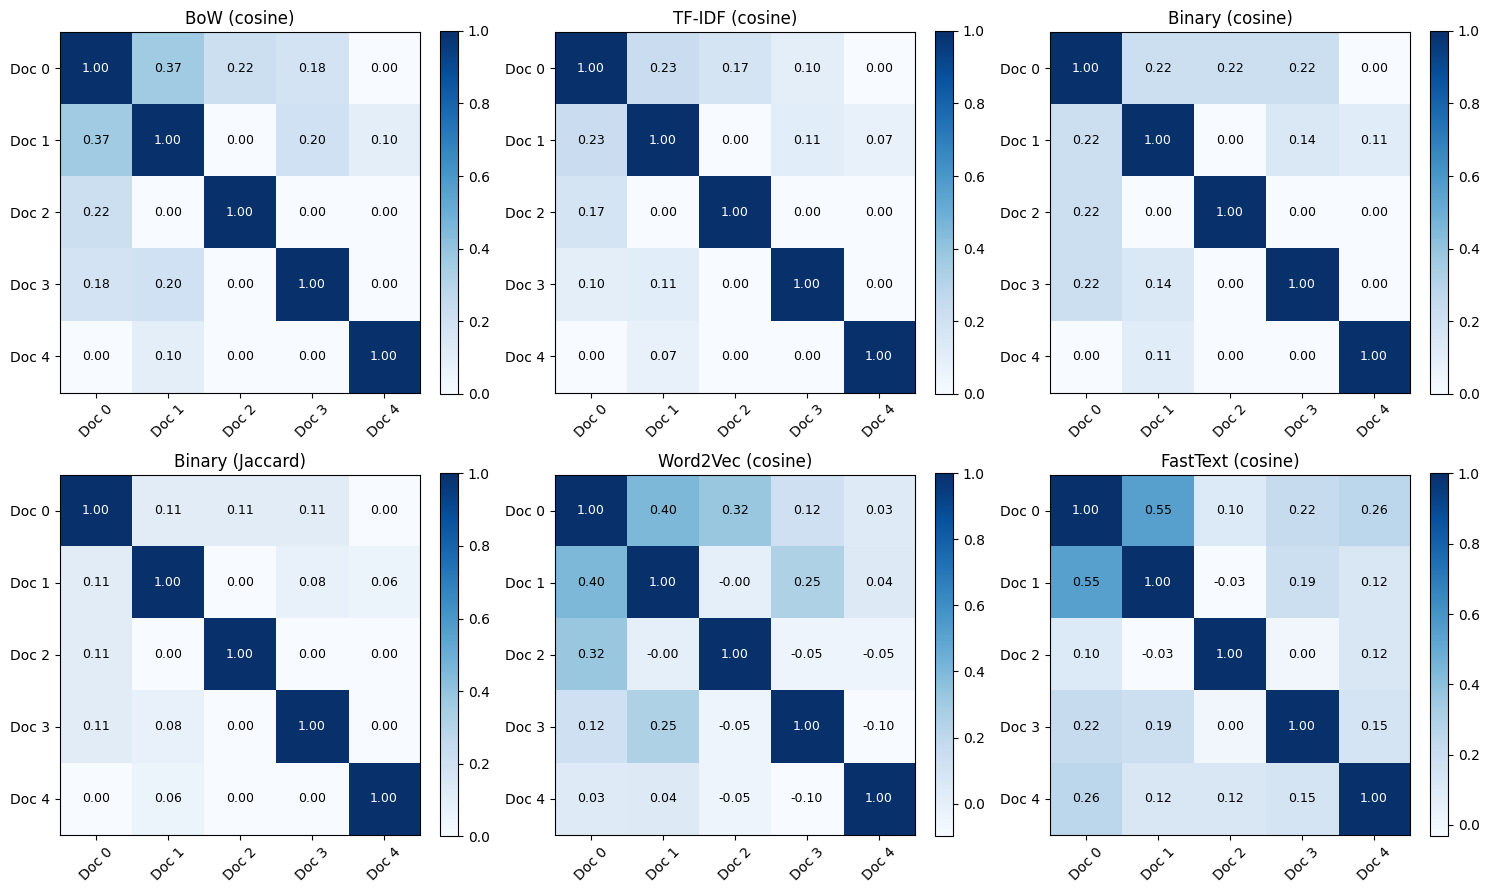

In [19]:
# Visualisasi: heatmap matriks similarity setiap metode
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, m) in zip(axes.ravel(), methods.items()):
    im = ax.imshow(m, cmap='Blues', vmin=min(0, m.min()), vmax=1)
    ax.set_title(name)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for a in range(len(labels)):
        for b in range(len(labels)):
            ax.text(b, a, f"{m[a, b]:.2f}", ha='center', va='center',
                    color='white' if m[a, b] > 0.6 else 'black', fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 5. Pencarian Dokumen Berdasarkan Query

In [20]:
def query_similarity(query):
    q = preprocessing(query)
    q_tokens = word_tokenize(q)
    print(f"Query: '{query}'  ->  setelah preprocessing: '{q}'")

    hasil = {}
    hasil['BoW (cosine)']      = cosine_similarity(X_bow,   vectorizer_bow.transform([q]))[:, 0]
    hasil['TF-IDF (cosine)']   = cosine_similarity(X_tfidf, vectorizer_tfidf.transform([q]))[:, 0]
    q_bin = vectorizer_ohe.transform([q]).toarray()
    hasil['Binary (cosine)']   = cosine_similarity(X_bin, q_bin)[:, 0]
    hasil['Binary (Jaccard)']  = 1 - cdist(X_bin, q_bin, metric='jaccard')[:, 0]
    q_w2v = get_document_vector(q_tokens, model_w2v).reshape(1, -1)
    q_ft  = get_document_vector(q_tokens, model_ft).reshape(1, -1)
    hasil['Word2Vec (cosine)'] = cosine_similarity(X_w2v, q_w2v)[:, 0]
    hasil['FastText (cosine)'] = cosine_similarity(X_ft,  q_ft)[:, 0]

    return pd.DataFrame(hasil, index=labels)

def top_k(df_scores, k=3):
    rows = []
    for name in df_scores.columns:
        order = df_scores[name].sort_values(ascending=False).head(k)
        rows.append({'metode': name,
                     **{f'Top {r+1}': f"{idx} ({val:.3f})" for r, (idx, val) in enumerate(order.items())}})
    return pd.DataFrame(rows).set_index('metode')

In [21]:
# Query 1: semua kata ada di vocabulary
scores_1 = query_similarity("retro website")
scores_1.round(3)

Query: 'retro website'  ->  setelah preprocessing: 'retro website'


,BoW (cosine),TF-IDF (cosine),Binary (cosine),Binary (Jaccard),Word2Vec (cosine),FastText (cosine)
Doc 0,0.816,0.724,0.816,0.667,0.856,0.893
Doc 1,0.447,0.314,0.267,0.125,0.494,0.571
Doc 2,0.267,0.241,0.267,0.125,0.382,0.131
Doc 3,0.224,0.139,0.267,0.125,0.169,0.225
Doc 4,0.000,0.000,0.000,0.000,0.032,0.223


In [22]:
top_k(scores_1)

,Top 1,Top 2,Top 3
metode,,,
BoW (cosine),Doc 0 (0.816),Doc 1 (0.447),Doc 2 (0.267)
TF-IDF (cosine),Doc 0 (0.724),Doc 1 (0.314),Doc 2 (0.241)
Binary (cosine),Doc 0 (0.816),Doc 1 (0.267),Doc 2 (0.267)
Binary (Jaccard),Doc 0 (0.667),Doc 1 (0.125),Doc 2 (0.125)
Word2Vec (cosine),Doc 0 (0.856),Doc 1 (0.494),Doc 2 (0.382)
FastText (cosine),Doc 0 (0.893),Doc 1 (0.571),Doc 3 (0.225)


In [23]:
# Query 2: kata 'browser' (tunggal) TIDAK ada di vocabulary, yang ada hanya 'browsers'
scores_2 = query_similarity("modern browser")
scores_2.round(3)

Query: 'modern browser'  ->  setelah preprocessing: 'modern browser'


,BoW (cosine),TF-IDF (cosine),Binary (cosine),Binary (Jaccard),Word2Vec (cosine),FastText (cosine)
Doc 0,0.000,0.000,0.000,0.000,-0.161,-0.149
Doc 1,0.000,0.000,0.000,0.000,-0.102,0.036
Doc 2,0.000,0.000,0.000,0.000,0.013,-0.122
Doc 3,0.316,0.325,0.378,0.143,0.206,0.370
Doc 4,0.000,0.000,0.000,0.000,-0.214,0.091


In [24]:
top_k(scores_2)

,Top 1,Top 2,Top 3
metode,,,
BoW (cosine),Doc 3 (0.316),Doc 0 (0.000),Doc 1 (0.000)
TF-IDF (cosine),Doc 3 (0.325),Doc 0 (0.000),Doc 1 (0.000)
Binary (cosine),Doc 3 (0.378),Doc 0 (0.000),Doc 1 (0.000)
Binary (Jaccard),Doc 3 (0.143),Doc 0 (0.000),Doc 1 (0.000)
Word2Vec (cosine),Doc 3 (0.206),Doc 2 (0.013),Doc 1 (-0.102)
FastText (cosine),Doc 3 (0.370),Doc 4 (0.091),Doc 1 (0.036)


In [25]:
# Mengapa 'browser' tidak dikenali oleh BoW/TF-IDF/Word2Vec tetapi FastText tetap menghasilkan vektor?
print("'browser' ada di vocabulary BoW   ?", 'browser' in vectorizer_bow.vocabulary_)
print("'browser' ada di vocabulary W2V   ?", 'browser' in model_w2v.wv.key_to_index)
print("'browser' ada di vocabulary FT    ?", 'browser' in model_ft.wv.key_to_index)
print("'browser' punya vektor di FastText?", 'browser' in model_ft.wv, "(dari n-gram, mis. 'bro', 'row', 'ows', ...)")

'browser' ada di vocabulary BoW   ? False
'browser' ada di vocabulary W2V   ? False
'browser' ada di vocabulary FT    ? False
'browser' punya vektor di FastText? True (dari n-gram, mis. 'bro', 'row', 'ows', ...)


### Kesimpulan
Semua metode menghasilkan kesimpulan yang konsisten: Doc 0 – Doc 1 adalah pasangan paling mirip, karena sama-sama memuat kata retro.

Representasi berbasis kata (BoW, TF-IDF, binary, dan Jaccard) mudah dijelaskan karena setiap nilai bisa ditelusuri ke kata yang sama. Kelemahannya, 5 dari 10 pasangan bernilai 0 dan variasi bentuk kata seperti website/websites atau browser/browsers tidak dikenali. BoW dan TF-IDF menghasilkan urutan yang sama dengan nilai TF-IDF lebih kecil, karena keunggulan IDF baru terasa pada korpus yang lebih besar. Binary dan Jaccard menghasilkan banyak nilai seri karena hanya melihat ada atau tidaknya kata.

Word2Vec dan FastText memberi nilai untuk hampir semua pasangan dokumen, tetapi pada korpus 5 kalimat nilai tersebut banyak didominasi noise, sehingga tidak bisa dibaca sebagai kemiripan makna. FastText lebih baik daripada Word2Vec untuk kata yang tidak ada di vocabulary atau yang bentuknya bervariasi.

Keterbatasan: korpus hanya 5 kalimat. Untuk hasil word embedding yang bermakna dibutuhkan korpus jauh lebih besar atau model pre-trained. Kalau tetap memakai korpus ini, BoW atau TF-IDF dengan cosine similarity adalah pilihan yang paling mudah dipertanggungjawabkan. Penambahan stemming pada preprocessing juga akan menyatukan website dan websites, sehingga Doc 4 terhubung ke Doc 0 dan Doc 2.